# Start here: a guided tour of the Project Prairie Grass data

In July and August 1956, near O'Neill, Nebraska, sulphur dioxide was released from a point
source **0.46 m above a flat prairie** for ten minutes at a time. Samplers downwind measured
how much of it arrived. The experiment ran 70 times, by day and by night, in sunshine and
under clear-sky inversions. The result is a classic data set for **near-ground dispersion**.
It was used to build the Pasquill–Gifford dispersion curves that sit inside many regulatory
plume models today.

This repository has digitised the printed tables. This notebook shows you around:

1. **What was measured, and where**: the sampler layout.
2. **Which file holds what**, and how the tables join.
3. **One run, end to end**: gas released, wind, stability, plume.
4. **One table per run** (`pgdata.run_table()`), the starting point for the later notebooks.

| Notebook | Question |
|---|---|
| `04_descriptive_statistics` | What are the ranges? What looks odd? Which outliers are real? |
| `05_meteorology_and_stability` | Convection or inversion? Wind and temperature profiles, the diurnal cycle |
| `06_dispersion_modelling` | How wide and how tall is the plume? A Gaussian plume, checked against the data |
| `07_correlations` | Which run-level quantities move together, and why that can mislead |
| `01`–`03` | Structure checks, raw plume profiles, provenance and review |

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd()))  # notebooks/ (for pgdata)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import pgdata
pgdata.style()
pd.set_option("display.precision", 3); pd.set_option("display.max_columns", 40); pd.set_option("display.width", 160)

## 1. The field: five arcs and six towers

The samplers stood on **five semicircular arcs** at 50, 100, 200, 400 and 800 m from the source.
Each arc ran from due west through north to due east. The posts were 2° apart on the inner arcs
and 1° apart at 800 m, all at 1.5 m height. On the 100 m arc, **six towers** carried samplers
from 0.5 to 17.5 m. Bearings are compass bearings *from the source*. The plume travels
*downwind*, so it lands at the bearing opposite to the wind direction.

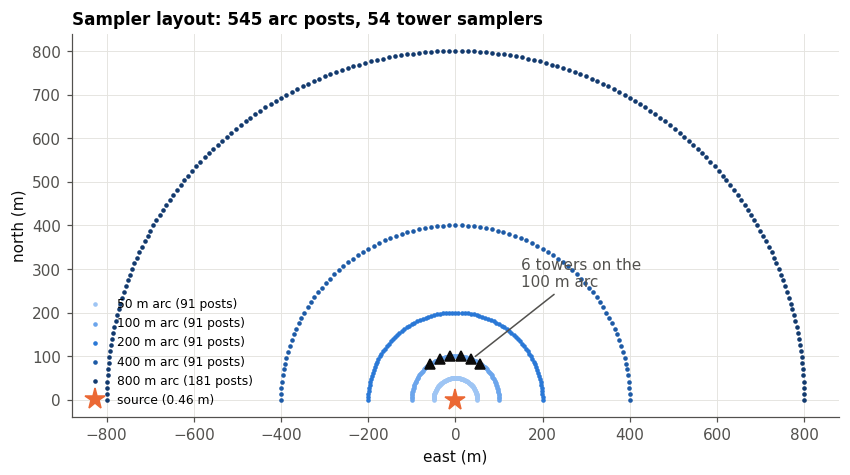

In [2]:
arcs, towers = pgdata.arcs(), pgdata.towers()
posts = arcs.drop_duplicates(["arc_m", "post"])[["arc_m", "post", "bearing_deg"]]
posts = posts.assign(x=posts.arc_m * np.sin(np.deg2rad(posts.bearing_deg)),
                     y=posts.arc_m * np.cos(np.deg2rad(posts.bearing_deg)))
tower_bearing = {t: (270 + 2 * (lo - 1) + 1) % 360 for t, lo in enumerate([28, 35, 42, 49, 56, 63], start=1)}

fig, ax = plt.subplots(figsize=(9, 5))
for arc, g in posts.groupby("arc_m"):
    ax.scatter(g.x, g.y, s=4, color=pgdata.ARC_COLORS[arc], label=f"{arc} m arc ({len(g)} posts)")
for t, b in tower_bearing.items():
    ax.plot(100 * np.sin(np.deg2rad(b)), 100 * np.cos(np.deg2rad(b)), "^", color=pgdata.INK, ms=6)
ax.plot(0, 0, "*", color="#eb6834", ms=14, label="source (0.46 m)")
ax.annotate("6 towers on the\n100 m arc", (40, 95), (150, 260), color=pgdata.MUTED,
            arrowprops=dict(arrowstyle="-", color=pgdata.MUTED))
ax.set_aspect("equal"); ax.set_xlabel("east (m)"); ax.set_ylabel("north (m)")
ax.set_title("Sampler layout: 545 arc posts, 54 tower samplers"); ax.legend(loc="lower left", fontsize=8)
plt.show()

## 2. The files and how they join

All data are **long format**: one row per printed cell. The key that ties everything together
is the **run number**, called `run` in Volume I and `release` in Volume II. Read it as a string,
because `35S` and `48S` are distinct runs.

| Question | File | Key |
|---|---|---|
| How much gas arrived where? | `volume1/dataset/arcs.csv`, `towers.csv` | run, arc/post or tower/height |
| How much gas was released? | `volume1/dataset/source_strength.csv` | run |
| Wind at the source during the release | `volume1/dataset/slow_response_wind.csv` | release |
| Temperature, wind and humidity profiles, radiation | `volume2/dataset/table_8.1.csv` | release, height |
| The same, hourly, between releases | `volume2/dataset/table_8.2.csv` | date, cst |
| Heat budget | `volume2/dataset/table_9.x`, `10.1` | release |
| Upper air (balloons, aircraft) | `volume2/dataset/table_12.1`, `13.1` | release / field test |

`pgdata.py` hides the reading rules (string keys, `keep_default_na=False`, units). Each loader
returns a tidy pandas frame:

In [3]:
pd.DataFrame({
    "loader": ["arcs()", "towers()", "source_strength()", "slow_wind()", "micromet()", "profiles('temperature')", "arc_summary()", "run_table()"],
    "shape": [str(f().shape) for f in [pgdata.arcs, pgdata.towers, pgdata.source_strength, pgdata.slow_wind,
                                       pgdata.micromet, lambda: pgdata.profiles("temperature"),
                                       pgdata.arc_summary, pgdata.run_table]],
    "one row per": ["arc sampler cell", "tower sampler cell", "run (Q, g/s)", "release (Table 6.1, wide)",
                    "printed micromet value (8.1)", "release × height", "run × arc (plume statistics)", "run (everything)"],
})

TypeError: stats() got an unexpected keyword argument 'include_groups'

**A word on blanks.** A blank cell in Table 5.2 means *no measurable concentration*. It is not
missing data. Most samplers on a 180° arc see nothing, because the plume is only a few tens of
degrees wide. That is why `arcs.csv` has 22,306 `not_measurable` cells and only 8,173 values.
When we integrate across the plume below we count blanks as zero, and we leave the 31 cells
printed `M` (missing) out of the sums.

## 3. One run, end to end

`show_run` puts what we know about a single release in one place. Change `RUN` and run the cell
again. Some good ones to try: **33** (a hot afternoon), **59** (a still night), **16** (strong
convection), **50** (a remark about a leaky vacuum line).

In [ ]:
rt = pgdata.run_table()
remarks = pd.read_csv(pgdata.DATASET / "run_remarks.csv", dtype=str, keep_default_na=False)

def show_run(run: str):
    r = rt.loc[run]
    print(f"Run {run}: {r.date} {r.time_cst} CST ({r.day_night}),  Q = {r.Q_g_s:.1f} g/s")
    print(f"  wind at source (2 m, 10 min): {r.u_source_10:.2f} m/s from {r.dir_source_10:.0f}°,  sigma_theta = {r.sigma_theta_source_10:.1f}°")
    print(f"  T(16 m) - T(0.5 m) = {r.dT_16_05:+.2f} °C,  bulk Ri = {r.Ri_b:+.3f}  ->  {r.regime}")
    for txt in remarks.loc[remarks.run == run, "remark"]:
        print("  remark:", txt)
    a = arcs[(arcs.run == run)].merge(posts[["arc_m", "post", "x", "y"]], on=["arc_m", "post"])
    v = a[a.status == "value"]
    fig, (m, p) = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.1, 1]})
    m.scatter(a.x, a.y, s=2, color=pgdata.GRID)
    sc = m.scatter(v.x, v.y, c=np.log10(v.concentration_mg_m3.clip(lower=0.01)), s=12, cmap="Blues", vmin=-1.5, vmax=3)
    if pd.notna(r.dir_source_10):  # arrow: where the wind blows TO
        b = np.deg2rad(r.dir_source_10 + 180)
        m.annotate("", (300 * np.sin(b), 300 * np.cos(b)), (0, 0), arrowprops=dict(arrowstyle="->", color="#eb6834", lw=2))
    m.plot(0, 0, "*", color="#eb6834", ms=12); m.set_aspect("equal")
    fig.colorbar(sc, ax=m, label="log10 mg m$^{-3}$", shrink=0.8); m.set_title(f"Run {run}: map (arrow = wind)")
    for arc in pgdata.ARCS_M:
        d = a[a.arc_m == arc].sort_values("post")
        p.plot(d.bearing_unwrapped, d.concentration_mg_m3.where(d.status == "value"), color=pgdata.ARC_COLORS[arc], label=f"{arc} m")
    p.set_yscale("log"); p.set_xlim(270, 450)
    p.set_xticks([270, 315, 360, 405, 450], ["W", "NW", "N", "NE", "E"]); p.set_ylabel("mg m$^{-3}$")
    p.set_title("Crosswind profiles"); p.legend(fontsize=8, ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.12))
    plt.show()

RUN = "33"
show_run(RUN)

In [ ]:
show_run("59")

Compare the two runs. On the hot afternoon (33) the plume is broad and fades quickly with
distance. On the still night (59) it is narrow and stays concentrated far downwind: the peak
at 800 m is far higher. **Atmospheric stability** produces that contrast, and the later
notebooks are about it.

## 4. One row per run

`pgdata.run_table()` joins the per-run quantities into one frame. Use it to navigate the data
set: sort it, filter it, plot it. Columns ending in `_50 … _800` are plume statistics per arc
from `arc_summary()`. The docstrings say which columns are **printed** and which are
**derived** here.

In [ ]:
cols = ["date", "time_cst", "Q_g_s", "u_ref", "dir_source_10", "sigma_theta_source_10", "dT_16_05", "Ri_b", "regime",
        "peak_50", "peak_800", "sigma_y_m_100"]
rt[cols].head(12)

In [ ]:
# e.g. the five most stable runs, and how far their plumes carried
rt.sort_values("Ri_b", ascending=False)[cols].head(5)

In [ ]:
print(pgdata.run_table.__doc__)